# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:**  Nisha
**Student ID:** 023-24-0178
**Section:** F
**GitHub:** Your GitHub Profile URL
**Kaggle:** Your Kaggle Profile URL
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**
- Task A: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [67]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [68]:
# Task 1 — load spam.csv, inspect shape/head/class balance


spam_df = pd.read_csv("spam.csv", encoding="latin-1")
spam_df = spam_df[["v1", "v2"]].copy()
spam_df.columns = ["label", "message"]

print("SMS Spam Dataset Shape:", spam_df.shape)
print("\nFirst 5 rows:")
display(spam_df.head())

print("\nClass Counts:")
print(spam_df["label"].value_counts())

print("\nClass Percentages:")
print(
    (spam_df["label"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nMissing values:")
print(spam_df[["label", "message"]].isnull().sum())

SMS Spam Dataset Shape: (5572, 2)

First 5 rows:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class Counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class Percentages:
label
ham     86.59%
spam    13.41%
Name: proportion, dtype: str

Missing values:
label      0
message    0
dtype: int64


In [69]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_df = pd.read_csv("Tweets.csv", encoding="utf-8")

print("Original Tweets Dataset Shape:", tweets_df.shape)
print("\nFirst 5 rows:")
display(tweets_df[["airline_sentiment", "text"]].head())

print("\nOriginal Sentiment Counts:")
print(tweets_df["airline_sentiment"].value_counts())

print("\nOriginal Sentiment Percentages:")
print(
    (tweets_df["airline_sentiment"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

tweets_df = tweets_df[
    tweets_df["airline_sentiment"].isin(["positive", "negative"])
].copy()

print("\nShape after removing neutral tweets:", tweets_df.shape)
print("\nRemaining Sentiment Counts:")
print(tweets_df["airline_sentiment"].value_counts())

print("\nRemaining Sentiment Percentages:")
print(
    (tweets_df["airline_sentiment"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nMissing values:")
print(tweets_df[["airline_sentiment", "text"]].isnull().sum())

Original Tweets Dataset Shape: (14640, 15)

First 5 rows:


,airline_sentiment,text
0,neutral,@VirginAmerica What @dhepburn said.
1,positive,@VirginAmerica plus you've added commercials t...
2,neutral,@VirginAmerica I didn't today... Must mean I n...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...



Original Sentiment Counts:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Original Sentiment Percentages:
airline_sentiment
negative    62.69%
neutral     21.17%
positive    16.14%
Name: proportion, dtype: str

Shape after removing neutral tweets: (11541, 15)

Remaining Sentiment Counts:
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64

Remaining Sentiment Percentages:
airline_sentiment
negative    79.53%
positive    20.47%
Name: proportion, dtype: str

Missing values:
airline_sentiment    0
text                 0
dtype: int64


**Answer 2 (Task A — spam):**

The SMS Spam dataset contains 5,572 messages. Each row represents one SMS message labelled as either ham (legitimate message) or spam (unwanted message). This is a binary classification problem because the model predicts one of two possible classes. The class counts and percentages are reported by the code above.

**Answer 2 (Task B — sentiment):**

The Twitter US Airline Sentiment dataset contains 14,640 tweets before filtering. Each row represents a tweet about an airline. Neutral tweets are removed, leaving only positive and negative tweets. This is a binary classification problem because the model predicts whether a tweet expresses positive or negative sentiment. The remaining row count and exact class balance are reported by the code above.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [70]:
# Task 3: Clean SMS messages

spam_df = spam_df.dropna(subset=["label", "message"]).copy()

spam_df["message"] = spam_df["message"].astype(str).str.lower()
spam_df["label"] = spam_df["label"].str.lower().str.strip()
spam_df = spam_df[spam_df["label"].isin(["ham", "spam"])].copy()

print("Cleaned SMS dataset shape:", spam_df.shape)
display(spam_df.head())

Cleaned SMS dataset shape: (5572, 2)


,label,message
0,ham,"go until jurong point, crazy.. available only ..."
1,ham,ok lar... joking wif u oni...
2,spam,free entry in 2 a wkly comp to win fa cup fina...
3,ham,u dun say so early hor... u c already then say...
4,ham,"nah i don't think he goes to usf, he lives aro..."


In [71]:
# Task 4: Encode labels and split the data

X_spam = spam_df["message"]
y_spam = spam_df["label"].map({"ham": 0, "spam": 1})

X_train_spam, X_test_spam, y_train_spam, y_test_spam = train_test_split(
    X_spam,
    y_spam,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_spam
)
spam_vectorizer = CountVectorizer(stop_words=None)

X_train_spam_vec = spam_vectorizer.fit_transform(X_train_spam)
X_test_spam_vec = spam_vectorizer.transform(X_test_spam)

print("Training messages:", len(X_train_spam))
print("Testing messages:", len(X_test_spam))
print("Training vocabulary size:", len(spam_vectorizer.get_feature_names_out()))
print("Training matrix shape:", X_train_spam_vec.shape)
print("Testing matrix shape:", X_test_spam_vec.shape)

Training messages: 4457
Testing messages: 1115
Training vocabulary size: 7701
Training matrix shape: (4457, 7701)
Testing matrix shape: (1115, 7701)


**Answer 4 (why fit on training data only):**

The vectorizer must be fitted only on the training data to prevent data leakage. Fitting it on the test messages would allow information from the test set to influence the vocabulary before evaluation. We use `fit_transform()` on training messages and only `transform()` on test messages to keep the evaluation fair.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

SMS Spam — Naive Bayes Metrics
Accuracy: 0.9839 (98.39%)
Precision: 0.9645 (96.45%)
Recall: 0.9128 (91.28%)
F1-score: 0.9379 (93.79%)


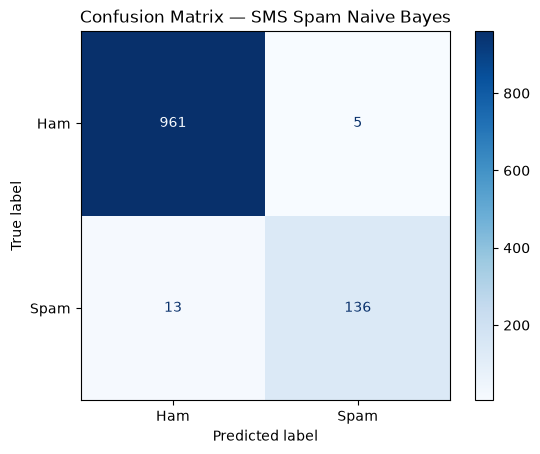

Confusion Matrix:
[[961   5]
 [ 13 136]]


In [72]:
# Task 5: Train and evaluate Multinomial Naive Bayes

spam_nb = MultinomialNB()
spam_nb.fit(X_train_spam_vec, y_train_spam)

y_pred_spam = spam_nb.predict(X_test_spam_vec)

spam_accuracy = accuracy_score(y_test_spam, y_pred_spam)
spam_precision = precision_score(y_test_spam, y_pred_spam, zero_division=0)
spam_recall = recall_score(y_test_spam, y_pred_spam, zero_division=0)
spam_f1 = f1_score(y_test_spam, y_pred_spam, zero_division=0)

spam_metrics = {
    "Accuracy": spam_accuracy,
    "Precision": spam_precision,
    "Recall": spam_recall,
    "F1-score": spam_f1
}

print("SMS Spam — Naive Bayes Metrics")
for metric, value in spam_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

# Confusion matrix: 0 = ham, 1 = spam
cm_spam = confusion_matrix(
    y_test_spam,
    y_pred_spam,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_spam,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — SMS Spam Naive Bayes")
plt.show()

print("Confusion Matrix:")
print(cm_spam)

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9839|
| Precision | 0.9645|
| Recall | 0.9128|
| F1-score | 0.9379|

**Answer 6:**

A false positive means a legitimate message is incorrectly classified as spam, while a false negative means a spam message is classified as ham. Both errors are undesirable, but a false positive can cause an important personal or business message to be missed. Therefore, I would prioritize precision to reduce legitimate messages being flagged as spam, while also monitoring recall to ensure that spam messages are detected. The final choice depends on the practical requirements of the messaging system.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [73]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_


feature_names = spam_vectorizer.get_feature_names_out()
class_names = spam_nb.classes_


ham_index = list(class_names).index(0)
spam_index = list(class_names).index(1)

spam_log_probs = spam_nb.feature_log_prob_[spam_index]
ham_log_probs = spam_nb.feature_log_prob_[ham_index]

top_spam_indices = np.argsort(spam_log_probs)[-15:][::-1]
top_ham_indices = np.argsort(ham_log_probs)[-15:][::-1]

top_spam_words = feature_names[top_spam_indices]
top_ham_words = feature_names[top_ham_indices]

print("Top 15 words associated with SPAM:")
print(", ".join(top_spam_words))

print("\nTop 15 words associated with HAM:")
print(", ".join(top_ham_words))

print("\nSpam word probabilities:")
display(pd.DataFrame({
    "Word": top_spam_words,
    "Log Probability": spam_log_probs[top_spam_indices]
}))

print("\nHam word probabilities:")
display(pd.DataFrame({
    "Word": top_ham_words,
    "Log Probability": ham_log_probs[top_ham_indices]
}))

Top 15 words associated with SPAM:
to, call, you, your, free, for, the, now, or, is, txt, ur, have, from, on

Top 15 words associated with HAM:
you, to, the, and, in, me, is, my, it, that, of, for, so, have, can

Spam word probabilities:


,Word,Log Probability
0,to,-3.658503
1,call,-4.342746
2,you,-4.487484
3,your,-4.609374
4,free,-4.786156
5,for,-4.872665
6,the,-4.872665
7,now,-4.934797
8,or,-4.980706
9,is,-5.064672



Ham word probabilities:


,Word,Log Probability
0,you,-3.600794
1,to,-3.839938
2,the,-4.160410
3,and,-4.407448
4,in,-4.458516
5,me,-4.560887
6,is,-4.569214
7,my,-4.575925
8,it,-4.625979
9,that,-4.892067


**Answer 7:**

The code identifies the 15 words with the highest estimated probability in the spam class and the 15 words with the highest estimated probability in the ham class. Spam-associated words may include promotional or prize-related terms, while ham-associated words may include ordinary conversational words. I will compare the actual output with my expectations. These words are associated with each class, but a word alone does not always determine whether a message is spam.

In [74]:
# Task 8: Test new SMS messages

my_messages = [
    "Congratulations! You have won a free prize. Claim your reward now!",
    "Hi, are we meeting for lunch today?",
    "URGENT! You have been selected for a cash reward. Call now!"
]
my_messages_clean = [message.lower() for message in my_messages]
my_messages_vec = spam_vectorizer.transform(my_messages_clean)
my_predictions = spam_nb.predict(my_messages_vec)
my_probabilities = spam_nb.predict_proba(my_messages_vec)

results = []

for message, prediction, probabilities in zip(
    my_messages,
    my_predictions,
    my_probabilities
):
    predicted_label = "Spam" if prediction == 1 else "Ham"

    results.append({
        "Message": message,
        "Predicted Label": predicted_label,
        "Ham Probability": round(probabilities[0], 4),
        "Spam Probability": round(probabilities[1], 4)
    })

display(pd.DataFrame(results))

,Message,Predicted Label,Ham Probability,Spam Probability
0,Congratulations! You have won a free prize. Cl...,Spam,0.0,1.0
1,"Hi, are we meeting for lunch today?",Ham,1.0,0.0
2,URGENT! You have been selected for a cash rewa...,Spam,0.0,1.0


**Answer 8:**

The first and third messages appear promotional and are expected to be classified as spam. The second message is an ordinary conversation and is expected to be classified as ham. I will compare these expectations with the model's actual predictions. Incorrect predictions can occur because the model learns word patterns from the training data rather than understanding the full meaning of a message.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [75]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
tweets_df = tweets_df.dropna(
    subset=["airline_sentiment", "text"]
).copy()
tweets_df = tweets_df[
    tweets_df["airline_sentiment"].isin(["positive", "negative"])
].copy()

def clean_tweet(text):
    text = str(text).lower()

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    text = re.sub(r"@\w+", " ", text)

    text = re.sub(r"#(\w+)", r"\1", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

tweets_df["clean_text"] = tweets_df["text"].apply(clean_tweet)

X_tweet = tweets_df["clean_text"]
y_tweet = tweets_df["airline_sentiment"].map({
    "negative": 0,
    "positive": 1
})

X_train_tweet, X_test_tweet, y_train_tweet, y_test_tweet = train_test_split(
    X_tweet,
    y_tweet,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_tweet
)

tweet_vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tweet_vec = tweet_vectorizer.fit_transform(X_train_tweet)
X_test_tweet_vec = tweet_vectorizer.transform(X_test_tweet)

print("Filtered tweet dataset shape:", tweets_df.shape)
print("Training tweets:", len(X_train_tweet))
print("Testing tweets:", len(X_test_tweet))
print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))
print("Training matrix shape:", X_train_tweet_vec.shape)
print("Testing matrix shape:", X_test_tweet_vec.shape)

print("\nTraining class balance:")
print(y_train_tweet.value_counts().rename(index={
    0: "Negative",
    1: "Positive"
}))

print("\nTesting class balance:")
print(y_test_tweet.value_counts().rename(index={
    0: "Negative",
    1: "Positive"
}))

Filtered tweet dataset shape: (11541, 16)
Training tweets: 9232
Testing tweets: 2309
Vocabulary size: 20000
Training matrix shape: (9232, 20000)
Testing matrix shape: (2309, 20000)

Training class balance:
airline_sentiment
Negative    7342
Positive    1890
Name: count, dtype: int64

Testing class balance:
airline_sentiment
Negative    1836
Positive     473
Name: count, dtype: int64


**Answer 12:**

I converted tweet text to lowercase, removed URLs and @mentions, and retained hashtag words while removing the # symbol. URLs and usernames often add noise, while hashtag words may contain useful sentiment information. I used TF-IDF with unigrams and bigrams to represent individual words and two-word phrases. The vectorizer was fitted only on the training tweets to prevent data leakage.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Airline Sentiment — Naive Bayes Metrics
Accuracy: 0.8502 (85.02%)
Precision: 0.9922 (99.22%)
Recall: 0.2706 (27.06%)
F1-score: 0.4252 (42.52%)


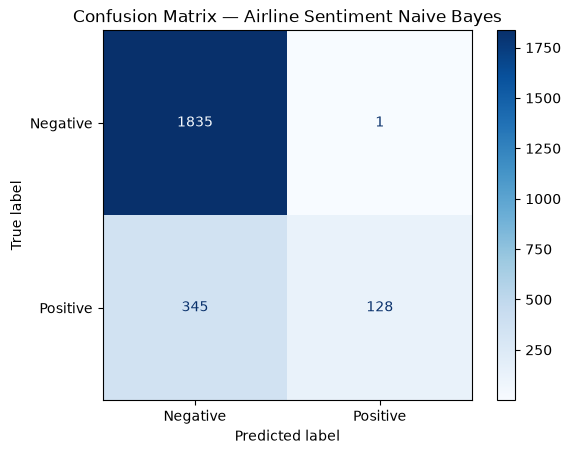

Confusion Matrix:
[[1835    1]
 [ 345  128]]


In [76]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
tweet_nb = MultinomialNB()
tweet_nb.fit(X_train_tweet_vec, y_train_tweet)

y_pred_tweet = tweet_nb.predict(X_test_tweet_vec)

tweet_accuracy = accuracy_score(y_test_tweet, y_pred_tweet)
tweet_precision = precision_score(y_test_tweet, y_pred_tweet, zero_division=0)
tweet_recall = recall_score(y_test_tweet, y_pred_tweet, zero_division=0)
tweet_f1 = f1_score(y_test_tweet, y_pred_tweet, zero_division=0)

tweet_metrics = {
    "Accuracy": tweet_accuracy,
    "Precision": tweet_precision,
    "Recall": tweet_recall,
    "F1-score": tweet_f1
}

print("Airline Sentiment — Naive Bayes Metrics")
for metric, value in tweet_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")
cm_tweet = confusion_matrix(
    y_test_tweet,
    y_pred_tweet,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tweet,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Airline Sentiment Naive Bayes")
plt.show()

print("Confusion Matrix:")
print(cm_tweet)

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.8502|
| Precision | 0.9922|
| Recall | 0.2706|
| F1-score | 0.4252|

**Answer 14:**

The Naive Bayes model's performance on airline sentiment should be compared with its performance on SMS spam using all four metrics. Spam classification can benefit from distinctive words and phrases that frequently occur in spam messages. Sentiment analysis is more challenging because the meaning of a tweet can depend on context, negation, sarcasm, and word combinations. Therefore, the word-independence assumption may be less reasonable for tweets, where the relationship between words can change the overall sentiment.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

In [77]:
# Task 17: Compare Naive Bayes performance

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A (Spam)": [
        spam_accuracy,
        spam_precision,
        spam_recall,
        spam_f1
    ],
    "Task B (Sentiment)": [
        tweet_accuracy,
        tweet_precision,
        tweet_recall,
        tweet_f1
    ]
})

display(
    comparison_df.style.format({
        "Task A (Spam)": "{:.4f}",
        "Task B (Sentiment)": "{:.4f}"
    })
)

AttributeError: The '.style' accessor requires jinja2

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

In [ ]:
# Task 18 — train Logistic Regression on Task A's vectorized features


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

**Answer 18 (which wins, and does it match expectations):**
_(your answer here)_

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
_(your answer here)_

**Answer 20 — Kaggle Notebook Links:**
- Task A: _______
- Task B: _______

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted